# Данные и Экспериментальная оценка методов синтеза голограмм

*В данном ноутбуке представлен анализ выборок и результатов исследования, проведённого на хакатоне по фотонике вместе с моими коллегами. Рассматривается история перехода от простых изображений к смешанным данным и методам без предварительного обучения.*

Основной **целью** было проверить, какие выводы о данных и архитектурах подтверждаются сохранёнными экспериментами.

Так же **дополнительной задачей** была подготовка воспроизводимых таблиц и иллюстраций для описания решения.

*Это перерасчёт сохранённых результатов, а не повторный запуск обучения. Новый общий сравнительный эксперимент выполняется в `01_photonic_solution.ipynb`.*

### **1. Инициализация и Источники данных**

Используются фактические манифесты v2/v3, сохранённые результаты DUSFN, командного репозитория и двух опытов без предварительного датасета. Контрольные суммы файлов проверяются при загрузке.

Одна **четвёрка** означает четыре целевых изображения и одну искомую фазовую маску. Количество изображений в четыре раза больше количества четвёрок; повторы случайных стартов не увеличивают число независимых входных примеров.

In [14]:
# @title Подготовка библиотек
import importlib.util
import subprocess
import sys
required = {'torch':'torch', 'numpy':'numpy', 'pandas':'pandas',
            'matplotlib':'matplotlib', 'seaborn':'seaborn', 'PIL':'Pillow'}
missing = [package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
import os, io, json, math, time, hashlib, zipfile, platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image as PILImage
from IPython.display import display, Image as DisplayImage, FileLink, Markdown
import torch
from torch import nn
import torch.nn.functional as F
torch.set_num_threads(min(4, os.cpu_count() or 1))

In [15]:
def configure_figures():
    from matplotlib import font_manager
    sns.set_theme(style='whitegrid', context='paper', font_scale=1.2)
    font = 'DejaVu Serif'
    try:
        font_manager.findfont('Times New Roman', fallback_to_default=False)
        font = 'Times New Roman'
    except ValueError:
        pass
    plt.rcParams.update({'figure.dpi': 300, 'font.family': 'serif',
                         'font.serif': [font], 'font.size': 10,
                         'pdf.fonttype': 42, 'ps.fonttype': 42})

def publish_figure(fig, name, output, show=True):
    output = Path(output); output.mkdir(parents=True, exist_ok=True)
    fig.savefig(output/f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(output/f'{name}.pdf', bbox_inches='tight')
    # Keep notebook outputs small enough for convenient GitHub rendering.
    preview = io.BytesIO()
    fig.savefig(preview, format='png', dpi=115, bbox_inches='tight')
    plt.close(fig)
    if show:
        display(DisplayImage(data=preview.getvalue()))

def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')

def export_public_results(output):
    """Allowlist result files. Private model checkpoints cannot enter this archive."""
    output = Path(output); archive_path = output.with_suffix('.zip')
    allowed = {'.csv', '.json', '.png', '.pdf', '.txt'}
    with zipfile.ZipFile(archive_path, 'w', zipfile.ZIP_DEFLATED) as archive:
        for path in sorted(output.rglob('*')):
            if path.is_file() and path.suffix.lower() in allowed:
                archive.write(path, str(path.relative_to(output)))
    with zipfile.ZipFile(archive_path) as archive:
        assert archive.testzip() is None
        assert not any(name.lower().endswith(('.pt', '.pth', '.ckpt', '.pkl')) for name in archive.namelist())
    return archive_path

def offer_download(path):
    print(f'[INFO] Results: {Path(path).name} | {Path(path).stat().st_size/1e6:.1f} MB')
    try:
        from google.colab import files
    except ImportError:
        display(FileLink(str(path)))
    else:
        files.download(str(path))

In [16]:
COLORS = ['#7A7A8C', '#E6397A', '#3F3F50', '#9D2356', '#BA90AA', '#ADB2C3', '#D9B6C5', '#666575']
COMPOSITIONS = {
    'independent_same_family':'Same-family independent',
    'independent_mixed_family':'Mixed-family independent',
    'linked_scene_layers':'Linked image layers',
    'partially_repeated_planes':'Partially repeated planes',
}


def read_embedded_sources(data):
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        source = {name: archive.read(name) for name in archive.namelist()}
    provenance = json.loads(source['provenance.json'])
    for name, digest in provenance['files_sha256'].items():
        assert hashlib.sha256(source[name]).hexdigest() == digest, name
    return source, provenance


def table_export(frame, name, output):
    frame.to_csv(Path(output)/f'{name}.csv', index=False)
    display(frame.round(4))


def build_dataset_inventory(manifest, v2, provenance):
    rows=[]
    for split, count in provenance['v1_counts'].items():
        rows.append({'dataset':'Small v1','split':split,'quartets':count,'images':4*count,
                     'content':'Procedural symbols, rings, shapes','role':'Supervised/self-supervised training inputs'})
    for split, summary in v2['summary'].items():
        rows.append({'dataset':'Mixed v2','split':split,'quartets':summary['scenes'],'images':4*summary['scenes'],
                     'content':'Fashion-MNIST + text + shapes + textures + lines','role':'Training inputs; targets interpreted as intensity in v2'})
    for split, group in manifest.groupby('split',sort=False):
        rows.append({'dataset':'Mixed v3','split':split,'quartets':len(group),'images':4*len(group),
                     'content':'Photos + EMNIST + Fashion-MNIST + synthetic targets','role':'Amplitude convention; diagnostic split separate'})
    rows.append({'dataset':'Diagnostic 12','split':'diagnostic','quartets':12,'images':48,
                 'content':'4 photos + 4 symbols + 4 smooth quartets','role':'Per-instance fitting and fixed comparison; no pretraining'})
    return pd.DataFrame(rows)


def plot_examples(samples, metadata, figures):
    # Two pages preserve legibility of both sparse symbols and dense photographs.
    groups = [[i for i,m in enumerate(metadata) if m['dataset'] in ['Small v1','Mixed v2','Team layers']],
              [i for i,m in enumerate(metadata) if m['dataset'] in ['Mixed v3','Diagnostic 12']]]
    for page, indices in enumerate(groups,1):
        fig, axes = plt.subplots(len(indices),4,figsize=(11,2.15*len(indices)),squeeze=False)
        for row,index in enumerate(indices):
            item=metadata[index]
            for plane in range(4):
                ax=axes[row,plane]
                ax.imshow(samples[index,plane],cmap='gray',vmin=0,vmax=255)
                ax.set_xticks([]);ax.set_yticks([]);ax.grid(False)
                if row==0:ax.set_title(f'Plane {plane+1}',fontweight='bold')
            axes[row,0].set_ylabel(item['dataset']+'\n'+item['description'],fontsize=9)
        fig.suptitle('Target Dataset Examples',fontsize=14,fontweight='bold',y=1.002)
        fig.tight_layout();publish_figure(fig,f'dataset_examples_{page}',figures)


def plot_composition(manifest,v2,figures):
    fig, axes=plt.subplots(1,2,figsize=(14,4.5))
    f=pd.DataFrame({split:item['families'] for split,item in v2['summary'].items()}).fillna(0).T
    f=f.div(f.sum(axis=1),axis=0)
    f.plot.bar(stacked=True,color=COLORS,ax=axes[0],width=.65)
    comp=pd.crosstab(manifest['split'],manifest['composition_type']).reindex(['train','val','test'])
    comp=comp[list(COMPOSITIONS)].fillna(0)
    comp.div(comp.sum(axis=1),axis=0).rename(columns=COMPOSITIONS).plot.bar(stacked=True,color=COLORS,ax=axes[1],width=.65)
    for ax,title in zip(axes,['Mixed v2: Image Families','Mixed v3: Quartet Composition']):
        ax.set_title(title,fontsize=14,fontweight='bold',pad=12)
        ax.set_ylabel('Observed Fraction',fontsize=12);ax.set_xlabel('Dataset Split',fontsize=12)
        ax.set_ylim(0,1);ax.tick_params(axis='x',rotation=0)
        ax.grid(axis='y',linestyle=':',alpha=.6);ax.grid(axis='x',visible=False)
        ax.legend(frameon=False,fontsize=8,loc='upper center',bbox_to_anchor=(.5,-.20),ncol=2)
        sns.despine(ax=ax)
    fig.tight_layout();publish_figure(fig,'dataset_composition',figures)


def plot_target_statistics(manifest,figures):
    fig,axes=plt.subplots(1,2,figsize=(14,4.5))
    for index,split in enumerate(['train','val','test']):
        group=manifest[manifest.split==split]
        for ax,column in zip(axes,['mean_intensity','fill_density']):
            ax.hist(group[column],bins=np.linspace(0,1,26),density=True,histtype='step',
                    lw=1.8,color=COLORS[index],label=split)
    for ax,title,label in zip(axes,['Brightness Distribution','Fill-Density Distribution'],['Mean Target Value','Non-Background Fraction']):
        ax.set_title(title,fontsize=14,fontweight='bold',pad=12)
        ax.set_xlabel(label,fontsize=12);ax.set_ylabel('Probability Density',fontsize=12)
        ax.grid(linestyle=':',alpha=.6);ax.legend(frameon=False);sns.despine(ax=ax)
    fig.tight_layout();publish_figure(fig,'target_statistics',figures)


def summarize_dusfn(per_plane,history,baselines,output,figures):
    assert len(per_plane)==4000 and per_plane.sample_id.nunique()==1000
    cases=per_plane.groupby(['sample_id','family','composition'],as_index=False)[['PCC','SSIM_local']].mean()
    by_family=cases.groupby('family',as_index=False).agg(quartets=('sample_id','size'),PCC=('PCC','mean'),SSIM=('SSIM_local','mean'))
    table_export(by_family,'dusfn_by_family',output)
    baseline_cases=baselines.groupby(['method','sample_id'],as_index=False)[['PCC','SSIM_local','time_ms_per_mask']].mean()
    baseline_summary=baseline_cases.groupby('method',as_index=False).agg(quartets=('sample_id','size'),PCC=('PCC','mean'),SSIM=('SSIM_local','mean'),milliseconds=('time_ms_per_mask','mean'))
    table_export(baseline_summary,'dusfn_baselines_8',output)
    fig,axes=plt.subplots(1,2,figsize=(14,4.5))
    x=np.arange(len(by_family))
    axes[0].bar(x-.19,by_family.PCC,width=.38,color=COLORS[0],label='PCC')
    axes[0].bar(x+.19,by_family.SSIM,width=.38,color=COLORS[1],label='SSIM')
    axes[0].set_xticks(x,by_family.family,rotation=35,ha='right')
    axes[0].set_ylabel('Mean Quality',fontsize=12);axes[0].set_title('DUSFN: 1,000 Test Quartets',fontsize=14,fontweight='bold')
    axes[0].legend(frameon=False);axes[0].grid(axis='y',linestyle=':',alpha=.6);axes[0].grid(axis='x',visible=False)
    axes[1].plot(history.epoch,history.val_PCC,color=COLORS[0],lw=1.7,label='Validation PCC')
    axes[1].plot(history.epoch,history.val_SSIM_local,color=COLORS[1],lw=1.7,label='Validation SSIM')
    axes[1].axvline(11,color=COLORS[2],linestyle='--',lw=1,label='Selected epoch: 11')
    axes[1].set_xlabel('Training Epoch',fontsize=12);axes[1].set_ylabel('Validation Quality',fontsize=12)
    axes[1].set_title('Archived Learning Curves',fontsize=14,fontweight='bold')
    axes[1].legend(frameon=False);axes[1].grid(linestyle=':',alpha=.6)
    for ax in axes:sns.despine(ax=ax)
    fig.tight_layout();publish_figure(fig,'dusfn_archived_results',figures)
    return cases,by_family,baseline_summary


def summarize_team(data,output,figures):
    mapping={'GS x300':'GS ×300', 'GS+ x300 (веса + связь)':'GS+ ×300',
        'M-2 (один проход, 60 мин)':'M2',
        'M-10 (GS x20 + 3 обуч. шага, срезы)':'M10',
        'M-10p (GS+ x20 + 3 обуч. шага, смесь)':'M10p',
        'гибрид GS+ x20 -> Adam x10':'GS+ → Adam'}
    rows=[]
    for method,label in mapping.items():
        for group,metrics in data[method].items():
            rows.append({'method':label,'target_group':group,'quartets_per_group':32,
                         'PCC':metrics['pcc'],'SSIM':metrics['ssim']})
    frame=pd.DataFrame(rows);table_export(frame,'team_test777_selected',output)
    fig,axes=plt.subplots(1,2,figsize=(14,4.5))
    for metric,ax in zip(['PCC','SSIM'],axes):
        matrix=frame.pivot(index='method',columns='target_group',values=metric).reindex(mapping.values())
        sns.heatmap(matrix,annot=True,fmt='.3f',cmap='PuRd',cbar=False,ax=ax,
                    linewidths=2,linecolor='white',annot_kws={'size':12})
        ax.set_title(f'Team Benchmark: {metric}',fontsize=14,fontweight='bold',pad=12)
        ax.set_xlabel('Target Group',fontsize=12);ax.set_ylabel('');ax.tick_params(axis='y',rotation=0)
    fig.tight_layout();publish_figure(fig,'team_benchmark',figures)
    return frame


def summarize_untrained(siren,decoder,provenance,output,figures):
    records=[];pairs=[]
    for name,frame in [('SIREN',siren),('DeepDecoder',decoder)]:
        gpu=provenance['siren_hardware' if name=='SIREN' else 'decoder_hardware']['gpu']
        # Average random starts first, so sample size stays 12 distinct quartets.
        by_case=frame.groupby(['case','type','method'],as_index=False)[['PCC','SSIM','seconds']].mean()
        summary=by_case.groupby('method',as_index=False)[['PCC','SSIM','seconds']].mean()
        summary.insert(0,'experiment',name);summary.insert(1,'hardware',gpu);summary['quartets']=12;summary['seeds']=2
        records.append(summary)
        neural=by_case[by_case.method==name].set_index('case')
        reference=by_case[by_case.method=='GS300_Adam'].set_index('case')
        for case in neural.index:
            pairs.append({'experiment':name,'case':case,'type':neural.loc[case,'type'],
                          'delta_PCC':neural.loc[case,'PCC']-reference.loc[case,'PCC'],
                          'delta_SSIM':neural.loc[case,'SSIM']-reference.loc[case,'SSIM']})
    summary=pd.concat(records,ignore_index=True);paired=pd.DataFrame(pairs)
    table_export(summary,'untrained_summary',output);table_export(paired,'untrained_paired_deltas',output)
    fig,axes=plt.subplots(1,2,figsize=(14,4.5))
    for ax,name in zip(axes,['SIREN','DeepDecoder']):
        block=paired[paired.experiment==name]
        x=np.arange(len(block));ax.bar(x-.19,block.delta_PCC,.38,color=COLORS[0],label='Δ PCC')
        ax.bar(x+.19,block.delta_SSIM,.38,color=COLORS[1],label='Δ SSIM')
        ax.axhline(0,color=COLORS[2],lw=.9)
        ax.set_xticks(x,block.case,rotation=65,ha='right',fontsize=8)
        ax.set_title(f'{name} − GS → Adam',fontsize=14,fontweight='bold',pad=12)
        ax.set_ylabel('Paired Quality Difference',fontsize=12);ax.legend(frameon=False)
        ax.grid(axis='y',linestyle=':',alpha=.6);ax.grid(axis='x',visible=False);sns.despine(ax=ax)
    fig.tight_layout();publish_figure(fig,'untrained_paired_comparison',figures)
    return summary,paired

In [17]:
def find_data_archive():
    candidates = [Path('/content/photonic_data.zip'), Path.cwd()/'photonic_data.zip']
    configured = os.environ.get('PHOTONIC_DATA_ARCHIVE')
    if configured:
        candidates.insert(0,Path(configured))
    for path in candidates:
        if path.is_file():
            return path
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Поместите photonic_data.zip рядом с ноутбуком.')
    print('Загрузите photonic_data.zip. Для первого ноутбука можно сразу выбрать и best.pt.')
    uploaded = files.upload()
    matches = [Path(name) for name in uploaded if Path(name).name == 'photonic_data.zip']
    del uploaded
    if len(matches) != 1:
        raise FileNotFoundError('Не выбран архив photonic_data.zip.')
    return matches[0]

DATA_ARCHIVE = find_data_archive()

def read_data_file(name):
    with zipfile.ZipFile(DATA_ARCHIVE) as archive:
        return archive.read(name)

In [18]:
SOURCE_BYTES = read_data_file('report_sources.zip')
assert hashlib.sha256(SOURCE_BYTES).hexdigest() == '8a1b9c22af28a6c1f400eb3878ac81fb15a9b537290f8558ed9a2ca18d83e4b1'

In [19]:
SAMPLE_BYTES = read_data_file('report_samples.npz')
assert hashlib.sha256(SAMPLE_BYTES).hexdigest() == '0353866f47faa500ab7eddf8db9523008a5e35fb8ac0349ece3147dbfe83dbbc'

In [20]:
configure_figures()
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
OUTPUT=Path.cwd()/f'photonic_data_report_{RUN_ID}'
FIGURES=OUTPUT/'figures';FIGURES.mkdir(parents=True,exist_ok=True)
sources,provenance=read_embedded_sources(SOURCE_BYTES)
with np.load(io.BytesIO(SAMPLE_BYTES),allow_pickle=False) as embedded:
    SAMPLES=embedded['targets'].copy()
del SOURCE_BYTES,SAMPLE_BYTES
manifest=pd.read_csv(io.BytesIO(sources['v3_manifest.csv']))
v2=json.loads(sources['v2_manifest.json'])
for name,data in sources.items():
    (OUTPUT/'sources').mkdir(exist_ok=True)
    (OUTPUT/'sources'/name).write_bytes(data)
print('[INFO] Source hashes: verified')
print('[INFO] Loaded v3 manifest:',len(manifest),'quartets')

[INFO] Source hashes: verified
[INFO] Loaded v3 manifest: 12400 quartets


### **2. Состав выборок и Эволюция смесей**

Первые эксперименты использовали простые символы и процедурные изображения. Затем были добавлены предметы, текстуры, фотографии и разные способы сочетания четырёх экранов.

| Этап | Из чего собирались цели | Для чего использовался |
| :--- | :--- | :--- |
| **Small v1** | Цифры, буквы, кольца и простая геометрия | Начальная проверка обучения и прямой физики; 320/48/10 четвёрок |
| **Mixed v2** | Fashion-MNIST, текст, фигуры, полутоновые текстуры, точки и линии | Более разнообразное обучение; 4096/256/256. Композиции: свободные, плотные, квадранты и общие координаты |
| **Командные фото** | Независимые фотографии; четыре слоя одной сцены по оценке глубины; объекты с фототекстурами | Проверка переноса с простых картинок на фотографии |
| **Командная смесь M10p** | 50% слоёв сцены, 30% независимых фото, 20% объектов с текстурами | Уменьшение привязки модели только к одному типу целей; это вероятности генератора, а не подсчитанные частоты готового архива |
| **Mixed v3** | DIV2K, EMNIST, Fashion-MNIST, фигуры, текст, плавные поля | 10000/1000/1000 и отдельно 400 диагностических четвёрок; несколько типов взаимосвязи экранов |
| **Diagnostic 12** | Фотографии, символы и плавные поля | Фиксированное сравнение методов подбора одной маски; 12 четвёрок, без этапа предобучения |

В v3 **независимые цели** выбираются из одного или разных семейств; **связанные** строятся из одного исходного изображения; **частично повторяющиеся** повторяют часть экранов. Связанные фото v3 выделяются яркостными окнами: их нельзя приравнивать к физической глубине сцены. Командные слои по оценке глубины — отдельный генератор.

*Важное различие: v2 разрабатывался с трактовкой яркости как интенсивности, последующие опыты — как нормированной амплитуды. Числа из этих протоколов нельзя складывать в общий рейтинг. Большой смешанный набор сам по себе не является доказательством лучшего качества.*

,dataset,split,quartets,images,content,role
0,Small v1,train,320,1280,"Procedural symbols, rings, shapes",Supervised/self-supervised training inputs
1,Small v1,val,48,192,"Procedural symbols, rings, shapes",Supervised/self-supervised training inputs
2,Small v1,test,10,40,"Procedural symbols, rings, shapes",Supervised/self-supervised training inputs
3,Mixed v2,train,4096,16384,Fashion-MNIST + text + shapes + textures + lines,Training inputs; targets interpreted as intens...
4,Mixed v2,val,256,1024,Fashion-MNIST + text + shapes + textures + lines,Training inputs; targets interpreted as intens...
5,Mixed v2,test,256,1024,Fashion-MNIST + text + shapes + textures + lines,Training inputs; targets interpreted as intens...
6,Mixed v3,train,10000,40000,Photos + EMNIST + Fashion-MNIST + synthetic ta...,Amplitude convention; diagnostic split separate
7,Mixed v3,val,1000,4000,Photos + EMNIST + Fashion-MNIST + synthetic ta...,Amplitude convention; diagnostic split separate
8,Mixed v3,test,1000,4000,Photos + EMNIST + Fashion-MNIST + synthetic ta...,Amplitude convention; diagnostic split separate
9,Mixed v3,diagnostic,400,1600,Photos + EMNIST + Fashion-MNIST + synthetic ta...,Amplitude convention; diagnostic split separate


,split,family,quartets
0,train,text,625
1,train,fashion,1208
2,train,shapes,816
3,train,gray_texture,651
4,train,points_lines,796
5,val,points_lines,45
6,val,shapes,49
7,val,text,41
8,val,gray_texture,42
9,val,fashion,79


,split,composition_type,quartets
0,diagnostic,canonical_control,20
1,diagnostic,independent_mixed_family,90
2,diagnostic,independent_same_family,104
3,diagnostic,linked_scene_layers,72
4,diagnostic,partially_repeated_planes,34
5,diagnostic,physical_forward_exact,80
6,test,independent_mixed_family,354
7,test,independent_same_family,308
8,test,linked_scene_layers,253
9,test,partially_repeated_planes,85


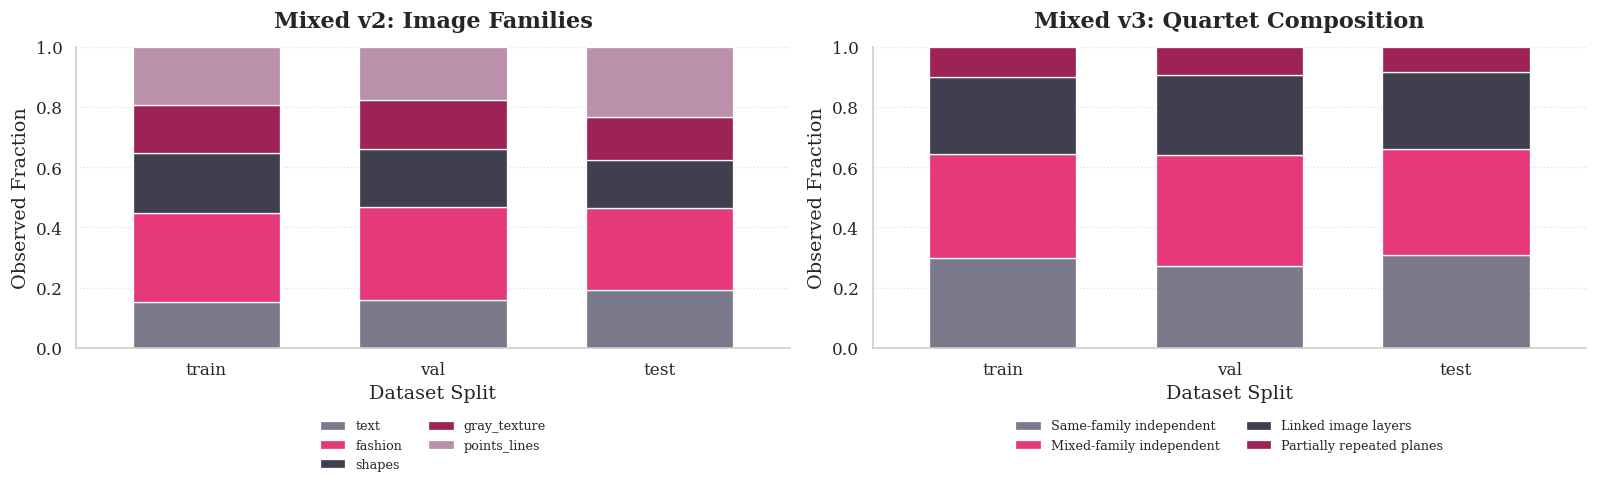

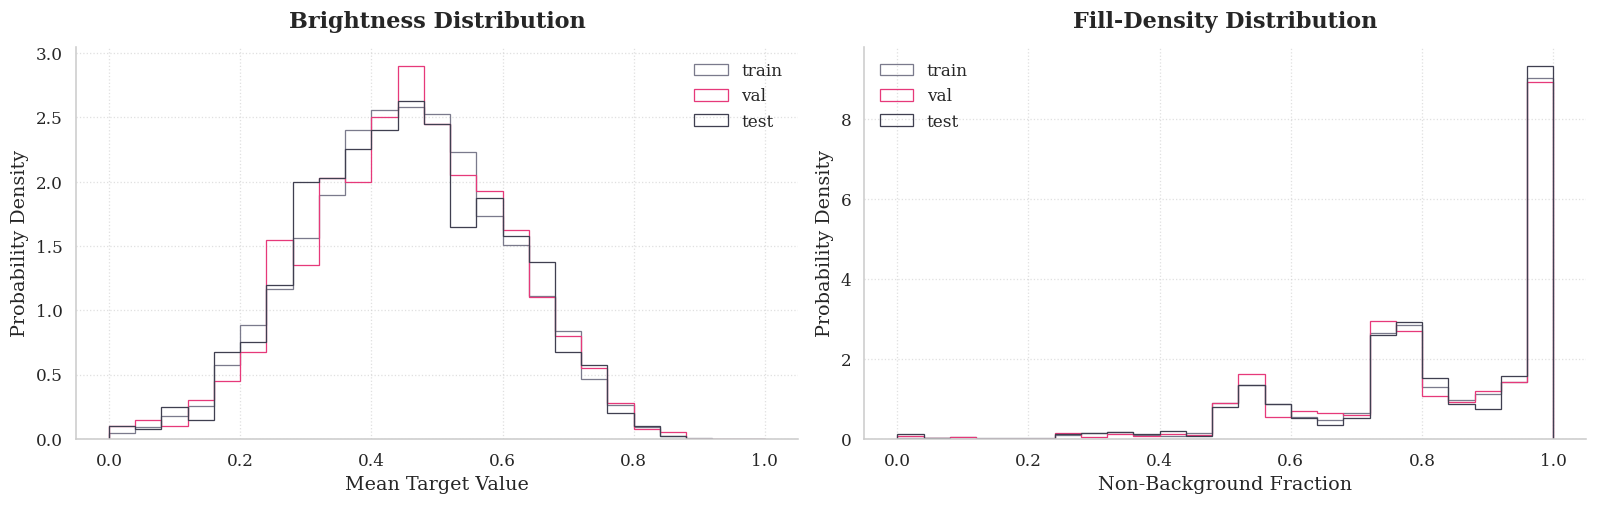

In [21]:
inventory=build_dataset_inventory(manifest,v2,provenance)
table_export(inventory,'dataset_inventory',OUTPUT)
v2_families=pd.DataFrame([{'split':split,'family':family,'quartets':count}
    for split,summary in v2['summary'].items() for family,count in summary['families'].items()])
table_export(v2_families,'v2_families',OUTPUT)
v3_counts=manifest.groupby(['split','composition_type']).size().rename('quartets').reset_index()
table_export(v3_counts,'v3_composition_counts',OUTPUT)
plot_composition(manifest,v2,FIGURES)
plot_target_statistics(manifest,FIGURES)

### **3. Визуальная верификация примеров**

Ниже показаны реальные пиксели из сохранённых наборов. Они иллюстрируют изменение состава целей; это не результаты реконструкции и не специально отобранные успешные предсказания.

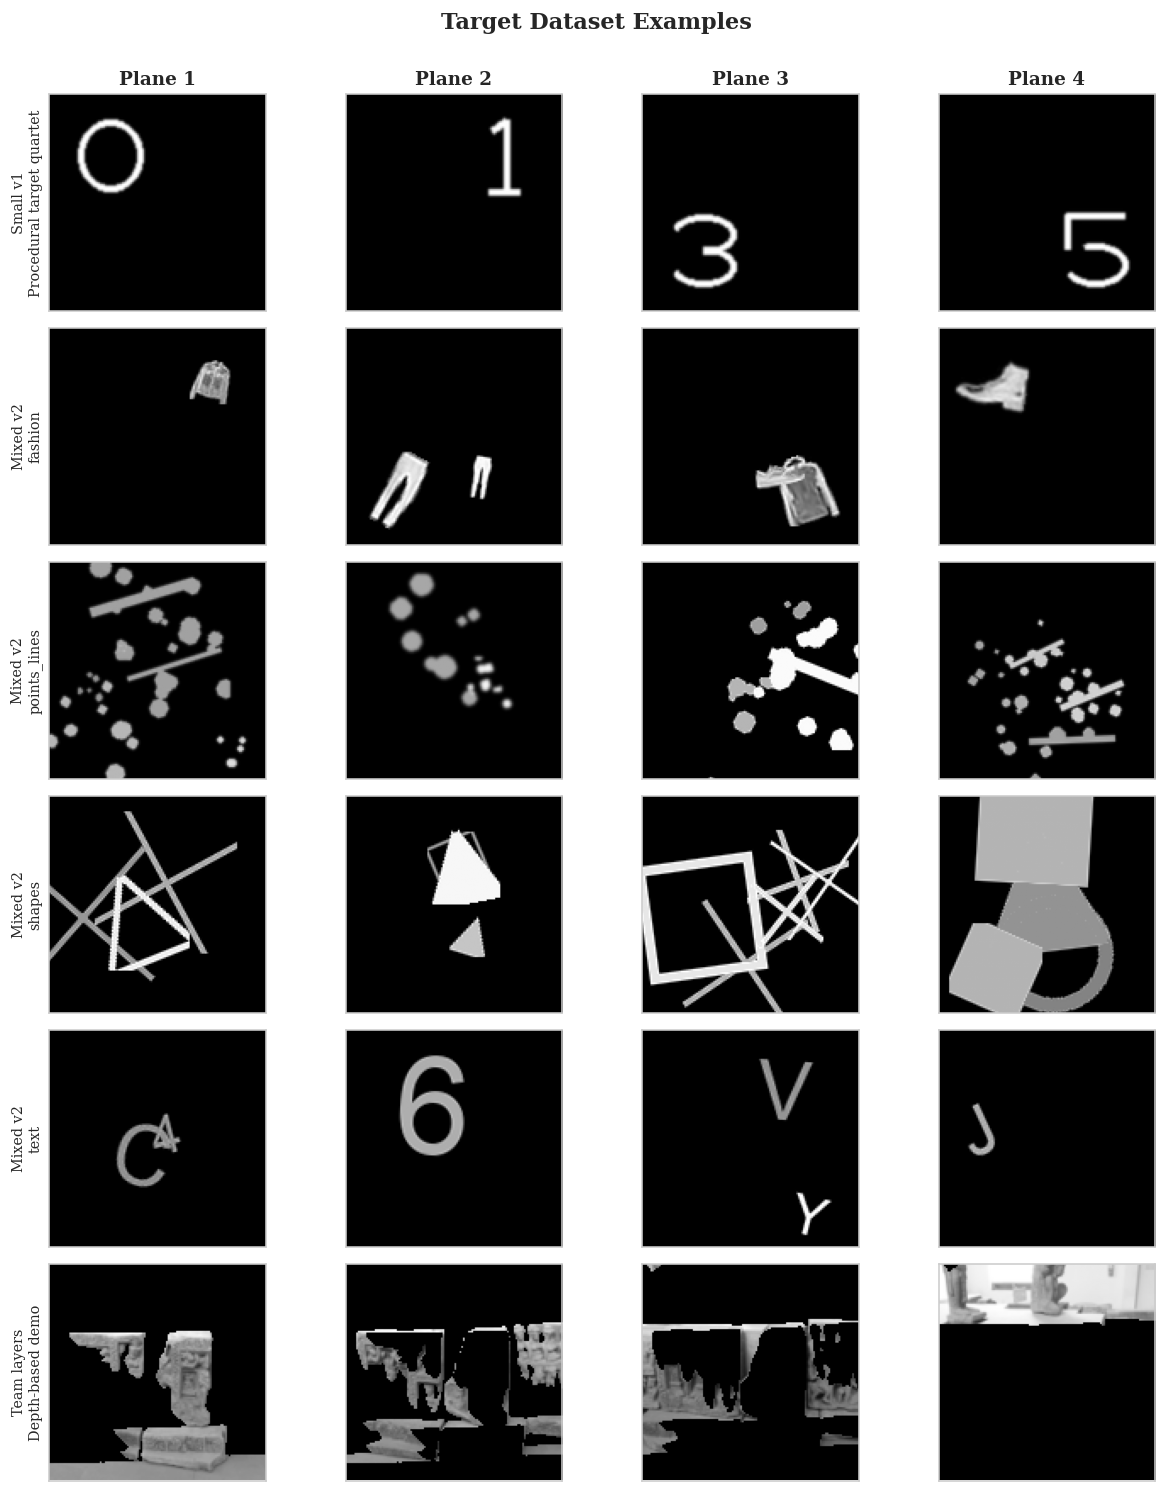

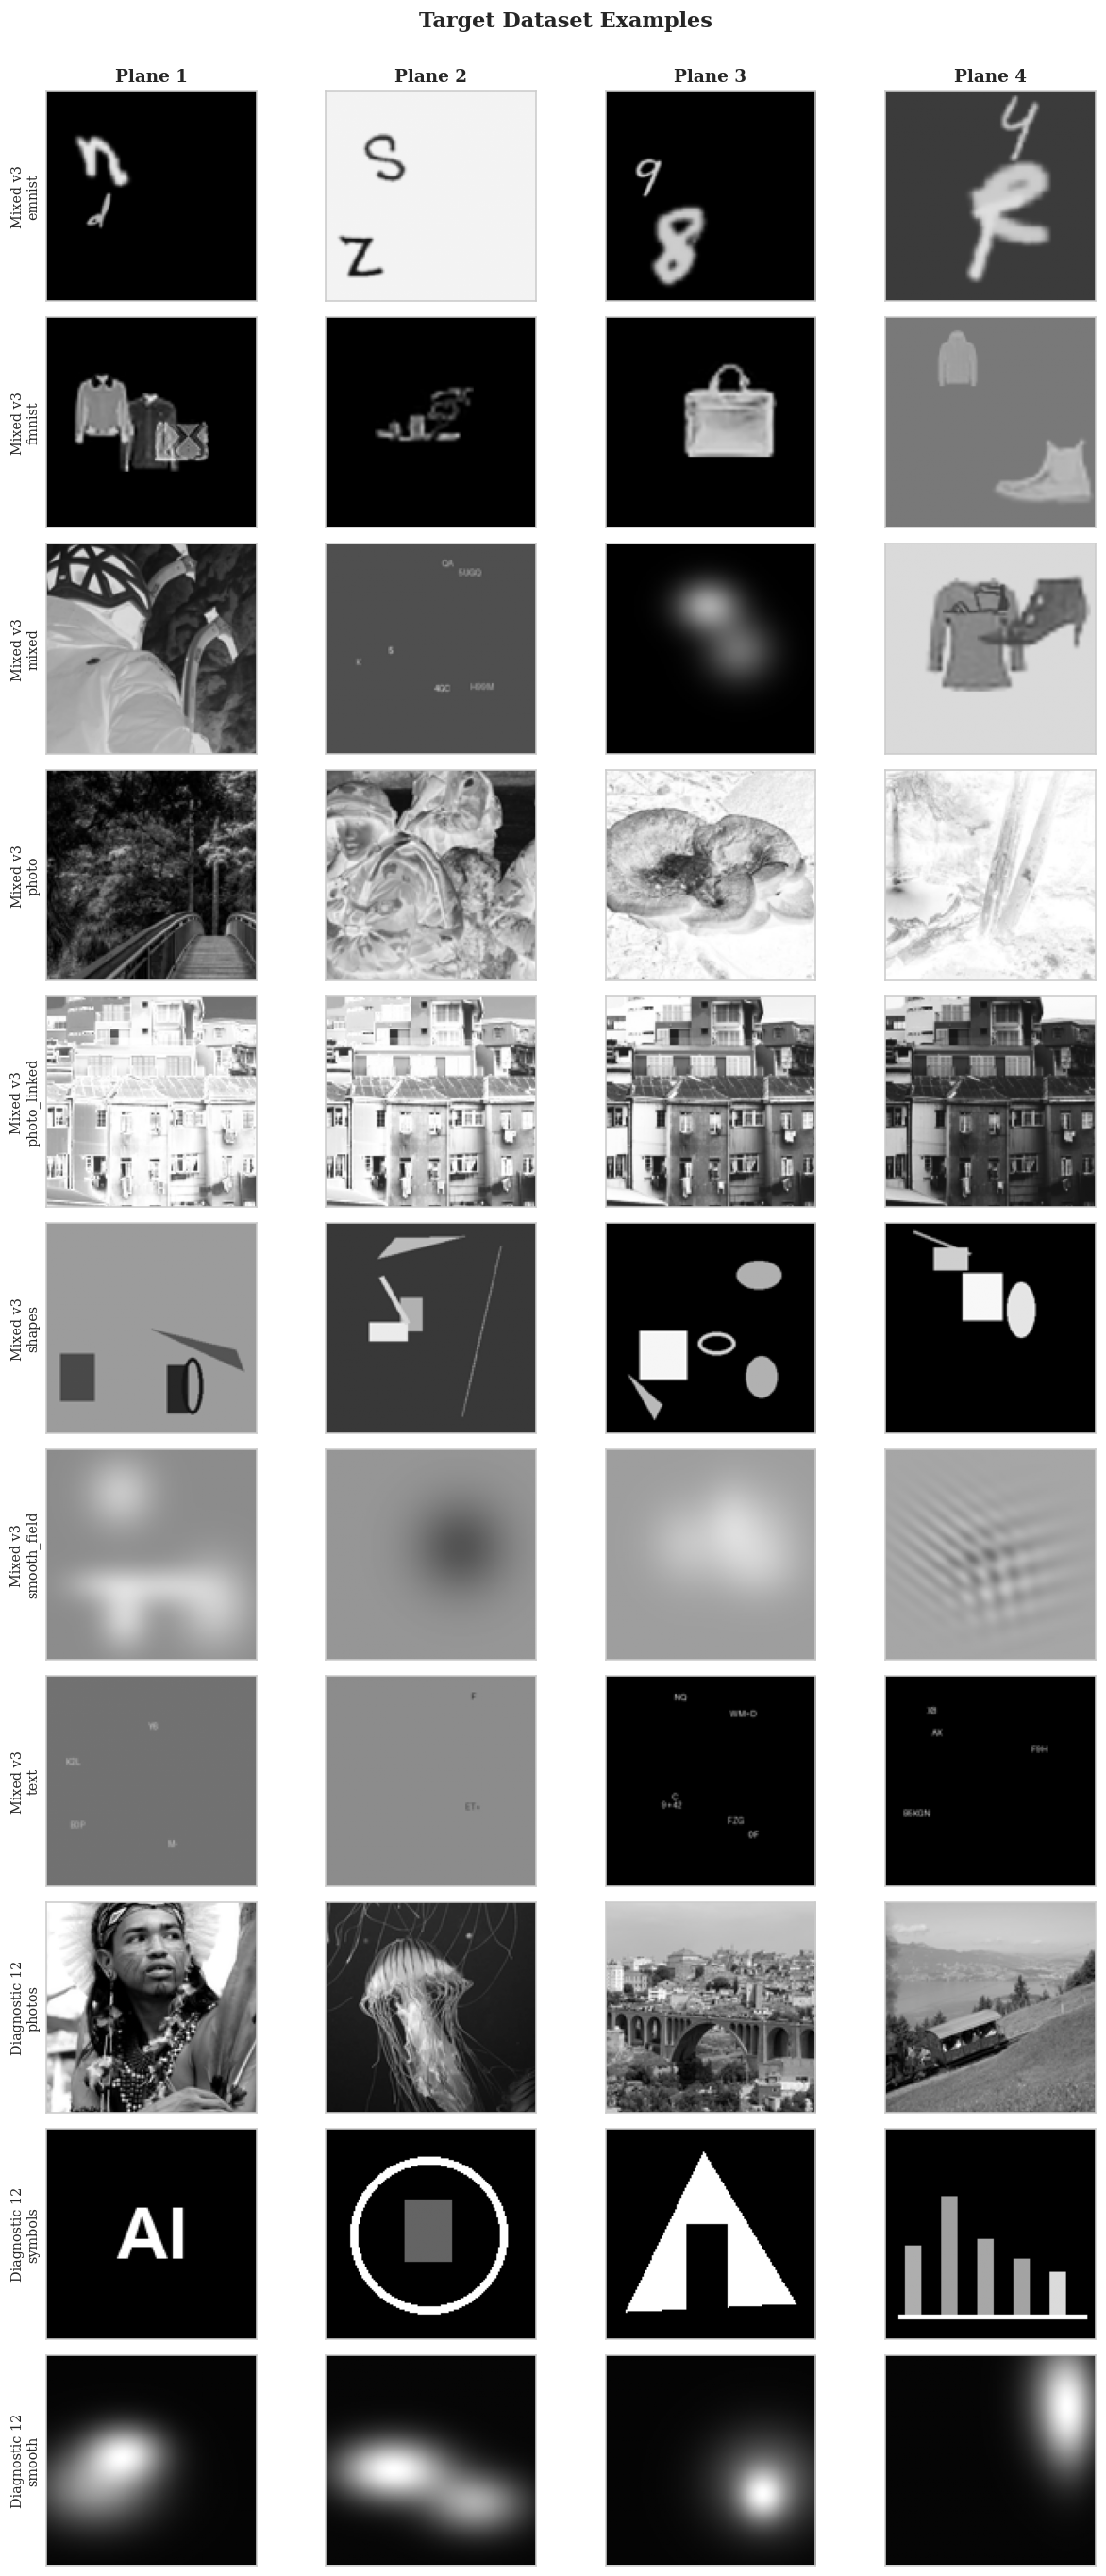

In [22]:
plot_examples(SAMPLES,provenance['sample_metadata'],FIGURES)

### **4. Предобученная сеть (DUSFN)**

**Задача:** получать маску новой четвёрки одним проходом готовой модели. **Данные:** v3, 10000 обучающих четвёрок. Правильные маски-ответы не требуются: обучение сравнивает целевые картинки с результатом прямого физического расчёта.

**Алгоритм:** предсказать начальные фазы → перенести четыре поля обратно на маску → выполнить шесть физических шагов со спектральными и свёрточными поправками. Лучшие сохранённые веса относятся к эпохе 11.

Качество полного test-раздела пересчитывается из **4000 строк по плоскостям, то есть 1000 четвёрок**. Отдельная сравнительная таблица содержит только **8 общих тестовых четвёрок** и замеры на A100. Эти две таблицы имеют разный охват и показываются отдельно.

,quartets,PCC,SSIM
0,1000,0.3981,0.4098


,family,quartets,PCC,SSIM
0,emnist,73,0.3752,0.4298
1,fmnist,67,0.4176,0.4332
2,mixed,353,0.3420,0.4143
3,photo,65,0.4194,0.3263
4,photo_linked,253,0.5105,0.3696
5,shapes,73,0.4088,0.4304
6,smooth_field,57,0.4508,0.4896
7,text,59,0.1699,0.4937


,method,quartets,PCC,SSIM,milliseconds
0,Adam200,8,0.3631,0.4734,794.9989
1,DUSFN,8,0.3744,0.4347,20.1573
2,DUSFN_Adam15,8,0.4073,0.4386,80.4815
3,GS10,8,0.2488,0.3539,4.9102
4,GS20_Adam15,8,0.3548,0.3832,68.5995
5,GS300,8,0.3570,0.2770,129.1621
6,GS50,8,0.3216,0.2837,22.1346


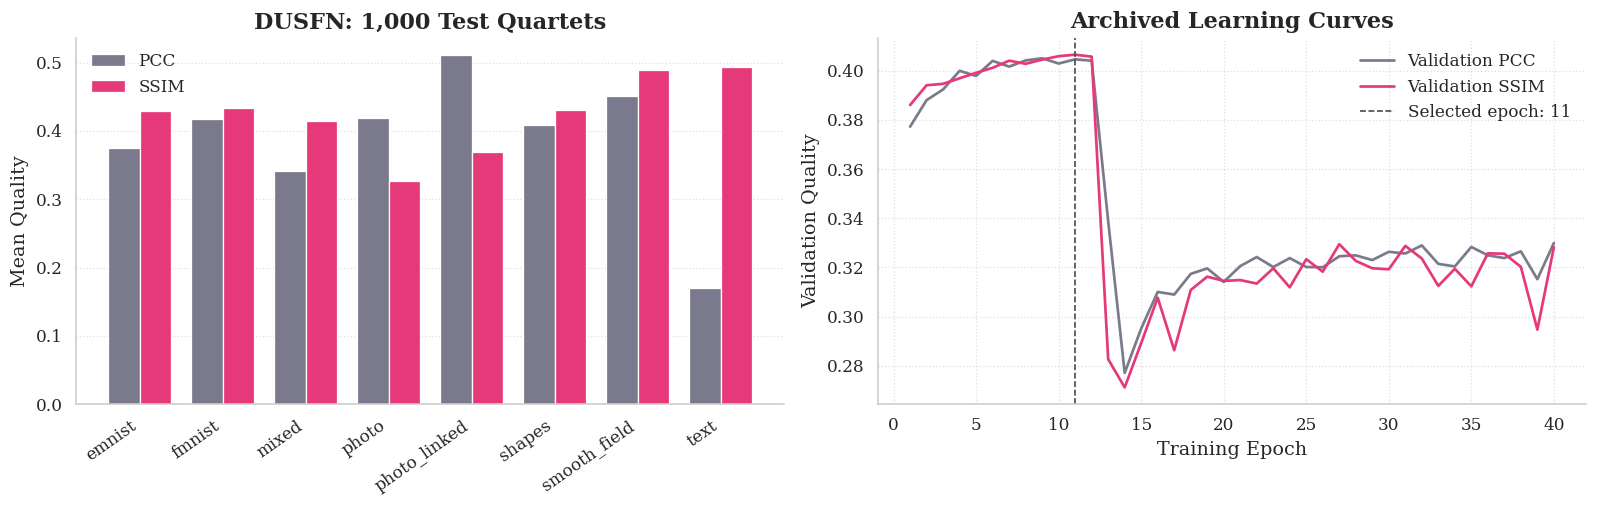

In [23]:
dusfn_test=pd.read_csv(io.BytesIO(sources['dusfn_test_per_plane.csv']))
history=pd.read_csv(io.BytesIO(sources['dusfn_history.csv']))
baselines=pd.read_csv(io.BytesIO(sources['dusfn_baselines.csv']))
full_test=dusfn_test.groupby('sample_id')[['PCC','SSIM_local']].mean()
display(pd.DataFrame([{'quartets':len(full_test),'PCC':full_test.PCC.mean(),'SSIM':full_test.SSIM_local.mean()}]).round(4))
dusfn_cases,dusfn_families,dusfn_baselines=summarize_dusfn(dusfn_test,history,baselines,OUTPUT,FIGURES)

На полном test-наборе DUSFN даёт примерно **PCC 0.3981 / SSIM 0.4098**. На восьми сравнительных примерах готовая сеть превосходит GS ×300 по обеим метрикам, но уступает Adam ×200 по SSIM. Это результат конкретной небольшой проверки, а не общая победа над физической оптимизацией.

Текстовые цели отдельно показывают ограничение одной метрики: SSIM около 0.494 сочетается с PCC около 0.170. Поэтому при выборе решения нужны обе метрики и просмотр четырёх восстановлений. Кривые также показывают, почему использованы лучшие сохранённые веса, а не последняя эпоха.

### **5. Командная серия (GS + Обученные поправки)**

Используется свежая проверка `e12_test777.json` из командного репозитория. В каждой группе по 32 четвёрки: слои сцены (`slices`), независимые фото (`indep`) и изображения, полученные прямым расчётом от существующей маски (`realizable`). Последняя группа заведомо имеет совместное физическое решение.

- **M2:** сеть пытается сразу предсказать маску по четырём целям.
- **M10:** сначала GS ×20, затем три обученных шага исправления; обучение на слоях сцены.
- **M10p:** GS с весами и обратной связью, затем обученные исправления; обучение на смеси 50/30/20.
- **GS+ → Adam:** физический начальный расчёт с последующим изменением пикселей фазы; предобученные веса не нужны.

*У M10p одновременно менялись начальный физический алгоритм и состав обучения. Поэтому отличие от M10 нельзя приписать только датасету. Ни одна из этих строк не служит прямым сравнением с DUSFN на её 1000 примерах.*

,method,target_group,quartets_per_group,PCC,SSIM
0,GS ×300,slices,32,0.4269,0.1645
1,GS ×300,indep,32,0.5183,0.3378
2,GS ×300,realizable,32,0.7465,0.6298
3,GS+ ×300,slices,32,0.4275,0.1723
4,GS+ ×300,indep,32,0.5235,0.3512
5,GS+ ×300,realizable,32,0.7294,0.6106
6,M2,slices,32,0.3113,0.1142
7,M2,indep,32,0.2301,0.1287
8,M2,realizable,32,0.3001,0.1916
9,M10,slices,32,0.3927,0.1810


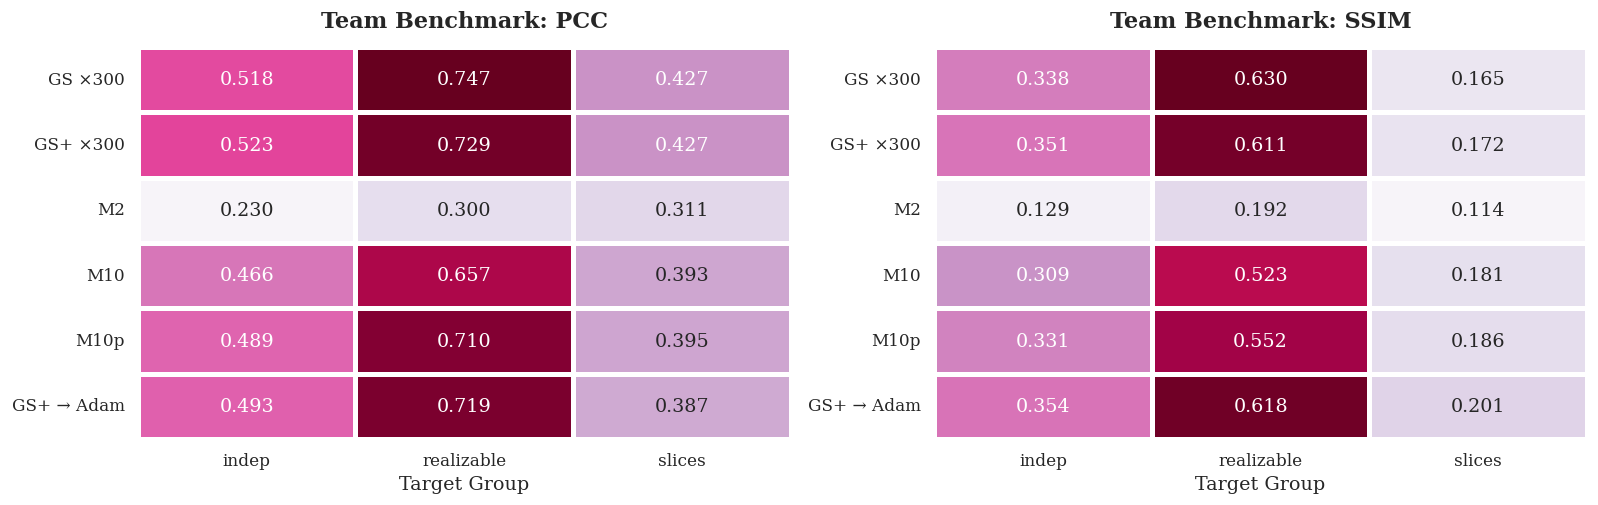

In [24]:
team_results=summarize_team(json.loads(sources['team_test777.json']),OUTPUT,FIGURES)

### **6. Методы без предварительного датасета**

**Задача:** найти маску только по текущим четырём изображениям. **Данные:** 12 фиксированных диагностических четвёрок. Для каждого метода использовались два случайных старта; основной бюджет подбора — 15 секунд на четвёрку, кроме отдельного ориентира GS ×300.

- **Прямая фаза:** изменяем сами пиксели маски, считаем четыре восстановления и уменьшаем ошибку.
- **SIREN:** небольшая сеть с синусными активациями получает координаты пикселя и выдаёт фазу. Под текущую четвёрку изменяются её веса; готового обучения на корпусе нет.
- **Deep Decoder:** небольшой свёрточный генератор превращает фиксированный шум в фазовую маску. Его веса также подбираются заново под каждую четвёрку.

Отсутствие предварительного датасета не означает отсутствие оптимизации: SIREN и Deep Decoder обучаются во время решения одного примера. GS и прямая фаза обходятся без нейросети.

Сравнение внутри каждого опыта выполнено на одном ускорителе: SIREN — **A100**, Deep Decoder — **L4**. Прямой рейтинг двух нейросетей между собой по этим запускам некорректен. На графике сначала усредняются два старта одной четвёрки, затем считается разность с её собственным GS → Adam; ноль означает равное качество.

,experiment,hardware,method,PCC,SSIM,seconds,quartets,seeds
0,SIREN,NVIDIA A100-SXM4-40GB,Adam_phase,0.5744,0.4068,15.0445,12,2
1,SIREN,NVIDIA A100-SXM4-40GB,GS300,0.5695,0.2319,0.1646,12,2
2,SIREN,NVIDIA A100-SXM4-40GB,GS300_Adam,0.5710,0.4434,15.0366,12,2
3,SIREN,NVIDIA A100-SXM4-40GB,GS_time,0.5896,0.2501,15.0051,12,2
4,SIREN,NVIDIA A100-SXM4-40GB,SIREN,0.5235,0.3768,15.0735,12,2
5,DeepDecoder,NVIDIA L4,Adam_phase,0.5748,0.4069,15.0460,12,2
6,DeepDecoder,NVIDIA L4,DeepDecoder,0.4839,0.3430,15.0510,12,2
7,DeepDecoder,NVIDIA L4,GS300,0.5695,0.2319,0.1630,12,2
8,DeepDecoder,NVIDIA L4,GS300_Adam,0.5709,0.4439,15.0349,12,2
9,DeepDecoder,NVIDIA L4,GS_time,0.5896,0.2502,15.0049,12,2


,experiment,case,type,delta_PCC,delta_SSIM
0,SIREN,photos_00,photos,-0.0512,-0.0615
1,SIREN,photos_01,photos,-0.0678,-0.0548
2,SIREN,photos_02,photos,-0.0475,-0.0490
3,SIREN,photos_03,photos,-0.0779,-0.0594
4,SIREN,smooth_00,smooth,-0.0510,-0.0345
5,SIREN,smooth_01,smooth,0.0015,0.1639
6,SIREN,smooth_02,smooth,-0.0512,-0.0294
7,SIREN,smooth_03,smooth,0.0074,0.1951
8,SIREN,symbols_00,symbols,-0.0506,-0.2170
9,SIREN,symbols_01,symbols,-0.0726,-0.2076


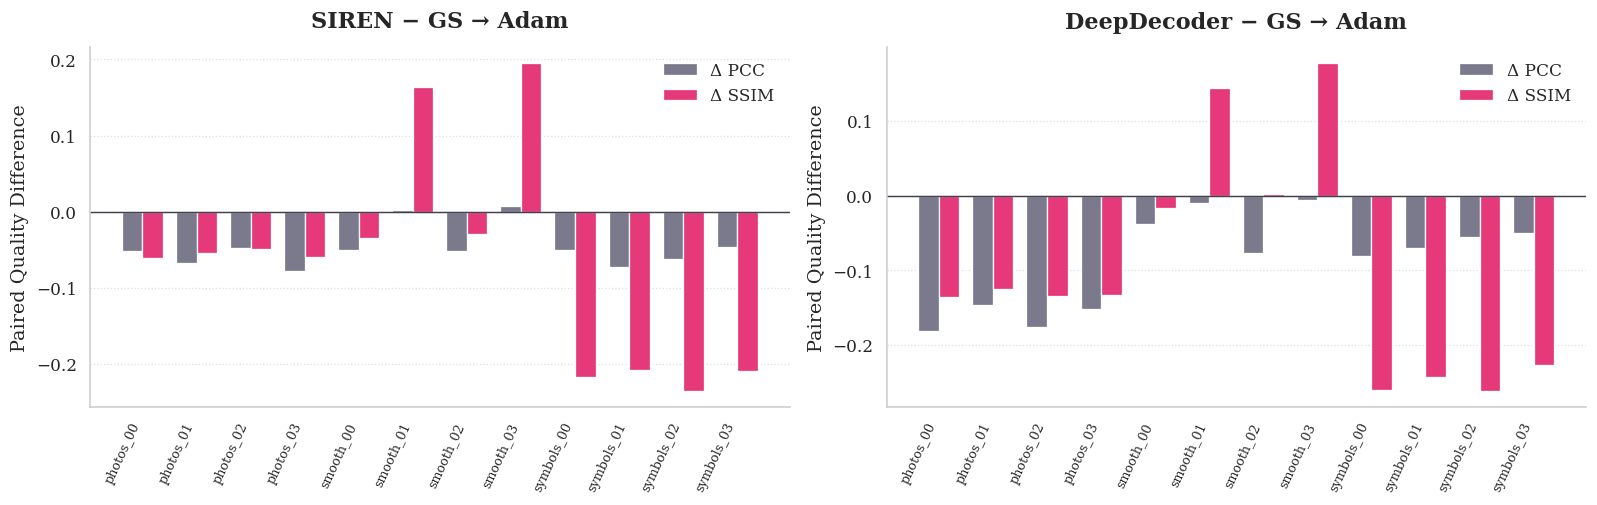

In [25]:
siren=pd.read_csv(io.BytesIO(sources['siren_runs.csv']))
decoder=pd.read_csv(io.BytesIO(sources['decoder_runs.csv']))
untrained_summary,paired=summarize_untrained(siren,decoder,provenance,OUTPUT,FIGURES)

Средние результаты SIREN: **0.5235 / 0.3768**, её GS → Adam: **0.5710 / 0.4434**. Deep Decoder: **0.4839 / 0.3430**, его GS → Adam: **0.5709 / 0.4439**. Универсальное преимущество необученного генератора не подтвердилось.

Эти опыты подтверждают более узкий практический вывод: **маску можно подбирать без предварительного корпуса**, и сильным ориентиром остаётся непосредственная оптимизация фазы. Они не доказывают, что предобучение бесполезно при ограничении на очень быстрый вывод.

Внимание и трансформеры были отдельным исследовательским вопросом. На этих данных нет полноценного контролируемого сравнения, которое позволило бы объявить attention причиной улучшения или готовым финальным решением.

### **7. Выводы и Экспорт иллюстраций**

Для практического сравнения оставлены две линии: **готовая DUSFN с возможным уточнением фазы** и **GS → Adam без предварительного датасета**. Их общий запуск реализован в первом ноутбуке; окончательный выбор зависит от качества, разрешённого времени и требования использовать обученную модель.

История смесей показывает увеличение разнообразия входов, но не изолированный эффект каждого источника. Для такого вывода потребовалось бы менять только данные при одной архитектуре и одинаковом протоколе обучения. В сохранённых опытах это условие часто не выполнялось.

Архив содержит использованные таблицы и манифесты, пересчитанные сводки и рисунки в PNG/PDF. Веса и обучающие архивы в него не входят. Загружаются только необходимые примеры и записи экспериментов, а не полные обучающие наборы.

Источники изображений: [DIV2K](https://data.vision.ee.ethz.ch/cvl/DIV2K/), [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist), [EMNIST](https://www.nist.gov/itl/products-and-services/emnist-dataset). .

In [26]:
save_json(OUTPUT/'analysis_manifest.json',{'run_id':RUN_ID,'source_archives':provenance['archives'],
    'team_commit':provenance['team_commit'],'weights_loaded':False,'training_performed':False,
    'new_model_benchmark':False,'distinct_diagnostic_quartets':12,'random_starts_per_quartet':2,
    'notes':'Archived protocols remain separate; no cross-dataset global ranking'})
archive_path=export_public_results(OUTPUT)
offer_download(archive_path)

[INFO] Results: photonic_data_report_20261107_203958.zip | 3.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>